In [4]:
## Data utilizada: # https://drive.google.com/drive/u/1/folders/1EoxsYIJd2mc5oRf2ZlbAS--bhw5E2MXa  Repertorio A
## Busca en la ambientes el que se llama ig-pipeline
## La primera vez debes reproducir el ambiente en la consola con uv sync (luego de esto ya va a estar disponible siempre)
## Luego solo lo buscas en Python enviroments (aunque se deberia seleccionar solo!)

import matplotlib.pyplot as plt
from seaborn import axes_style
import polars.selectors as cs
import seaborn.objects as so
import seaborn as sns
import polars as pl
import glob



pl.Config.set_tbl_rows(15)

polars.config.Config

In [2]:
# La siguiente función categoriza el espacio clonal en diferentes rangos según el porcentaje de clones presentes en la muestra.

def categorize_clone(clonal_space):
	if(clonal_space<= 0.01):
		return "Small (<=0.01%)"
	elif(clonal_space > 0.01 and clonal_space <= 0.1):
		return "Medium (0.01%-0.1%)"
	elif(clonal_space > 0.1 and clonal_space <= 0.5):
		return "Large (0.1%-0.5%)"
	elif(clonal_space > 0.5 and clonal_space <= 1):
		return "Expanded (0.5%-1%)"
	elif(clonal_space > 1):
		return "Hyperexpanded (>1%)"

# Orden para graficar las categorías
category_order = {
    "Small (<=0.01%)": 1,
    "Medium (0.01%-0.1%)": 2,
    "Large (0.1%-0.5%)": 3,
    "Expanded (0.5%-1%)": 4,
    "Hyperexpanded (>1%)": 5
}

# Colores por categoría 
colormap = {
        "Small (<=0.01%)": "#8bafd9",
        "Medium (0.01%-0.1%)": "#6a88ab",
        "Large (0.1%-0.5%)": "#4a6482",
        "Expanded (0.5%-1%)": "#c45d88",
        "Hyperexpanded (>1%)": "#9e647c",
    }

# Orden en el que se van a mostrar en el eje X
order_samples =[
	"A_30",
	"A_100",
	"A_200",
 	"A_400",
 	"A_800",
	"A_1000",
 	"A_1600",
 	"A_3200",
 	"A_6400",
 	"A_12800",
 	"A_25600",
 	"A_51200",
 	"A_102400"


]

# Modificar en caso de ser necesario
## Cantidad minima de lecturas para considerar un clon como válido
## !!! OJO QUE LOS RESULTADOS CON TUS DATOS CAMBIAN BASTANTE SI ES QUE ES MIN 1 O MIN 2
min_nreads_per_clone = 1
## Flag para indicar si se analizaran todas las lecturas o solo las productivas. 
## En caso de ser True, se analizaran solo las productivas. En caso de ser False, se analizaran todas las lecturas.
filter_by_productive = True


In [3]:
"""
Función para graficar el espacio clonal categorizado por muestra o grupo.
@param df_cat: DataFrame de polars con los datos categorizados. Columnas: 
  - sample, 
  - clon_type: categorias definidas en categorize_clone
  - clonal_space_occupied: porcentaje de ocupancia
  - order: orden de aparición de las barras
  - n_reads_max_cat: cantidad máxima de lecturas por categoría 
@param save: booleano que indica si se desea guardar la figura. Por defecto es False.
@param name: nombre para guardar la figura. Por defecto es "plot".
"""
def plot_categorized_clones(df_cat,show_by,save=False,name="plot"):
    plt.rcParams["figure.dpi"] = 300

    #df_category_summary_gby = df_cat.sort(show_by)
    order_dict = {nombre: i for i, nombre in enumerate(order_samples, start=1)}    
    df_category_summary_gby = df_cat.with_columns(
        order_ = pl.col("sample").replace(order_dict).cast(pl.Int64)
    )

    plot = (
        so.Plot(
            df_category_summary_gby.sort(["order_","order"]),
            x="sample",
            y="clonal_space_occupied",
            color="clon_type",
            #text="n_reads_max_cat"
        )
        .add(so.Bar(alpha=0.8, width=0.8), so.Stack(), legend=True)
        .scale(color=colormap)
        .layout(size=(12, 4), engine="tight")
    ).theme(
        {
            "axes.edgecolor": "#95999d",
            "axes.spines.right": False,
            "axes.spines.top": False,
        }
    )

    #plot = plot.facet(show_by).share(x=False).layout(engine="constrained")
    plot = plot.share(x=False).layout(engine="constrained")

    plot.config.theme.update(axes_style("white"))
    fig = plot.plot()
    if(save==True):
        plot.save(f"{basedir}/figures/{name}.svg", dpi=300, format='svg', bbox_inches='tight')
    return plot

In [4]:
## Input del notebook:
###- Múltiples archivos de clones: uno por cada muestra 
###    - (columnas: sequence_id, sequence, rev_comp, productive, ...., clone_id, etc) 
### Ejemplo: repertorio_A_insilico_30_seqs_clone-pass

In [5]:
basedir="../data/repertorio_A_clones/"


In [6]:
## Concatenamos los múltiples archivos en uno solo y añádimos una columna de file con el nombre del archivo

df_raw = pl.concat([
        (pl.read_csv(file, separator="\t")
         .with_columns(
             file=pl.lit(file)        
              )
             )
        for file in glob.glob(f"{basedir}/*tsv")]
)

## extraemos el nombre de la muestra (columna sample) y eliminamos el insilico
## eliminamos los alelos de la columna v_call (nueva columna v)
## redondeamos el porcentaje de homologia y pasamos a porcentaje (columna v_homology) 
df_raw = df_raw.with_columns(
    sample=(
        pl.col("file")
        .str.extract(r"repertorio_._clones/repertorio_(.*)_seqs.*", 1)
    ),
    
    v=pl.col("v_call").str.split("*").list.get(0),
    v_homology=(pl.col("v_identity") * 100).round(2),
).with_columns(sample = pl.col("sample").str.replace("insilico_",""))#.select("")

df_raw.select("sample").unique()
df_raw.head()


sequence_id,sequence,rev_comp,productive,v_call,d_call,j_call,sequence_alignment,germline_alignment,junction,junction_aa,v_cigar,d_cigar,j_cigar,stop_codon,vj_in_frame,locus,c_call,junction_length,np1_length,np2_length,v_sequence_start,v_sequence_end,v_germline_start,v_germline_end,d_sequence_start,d_sequence_end,d_germline_start,d_germline_end,j_sequence_start,j_sequence_end,j_germline_start,j_germline_end,v_score,v_identity,v_support,d_score,d_identity,d_support,j_score,j_identity,j_support,fwr1,fwr2,fwr3,fwr4,cdr1,cdr2,cdr3,clone_id,file,sample,v,v_homology
str,str,str,str,str,str,str,str,str,str,str,str,str,str,str,str,str,str,i64,i64,i64,i64,i64,i64,i64,i64,i64,i64,i64,i64,i64,i64,i64,f64,f64,f64,f64,f64,f64,f64,f64,f64,str,str,str,str,str,str,str,i64,str,str,str,f64
"""seq1940""","""ACAGTGCAGCTGGTGGAGTCTGGGGGAGGC…","""F""","""T""","""IGHV3-19*01""","""IGHD2-2*01,IGHD2-2*03,IGHD2/OR…","""IGHJ6*01""","""ACAGTGCAGCTGGTGGAGTCTGGGGGA...…","""ACAGTGCAGCTGGTGGAGTCTGGGGGA...…","""TGTGTGAGAAACTATGACTACTACTACTAC…","""CVRNYDYYYYGMDVW""","""296=""","""296S24N5=""","""301S3N59=""","""F""","""T""","""IGH""",null,45,0,0,1,296,1,320,297,301,25,29,302,360,4,62,463.0,1.0,2.5800e-132,10.3,1.0,192.0,114.0,1.0,1.8200e-29,"""ACAGTGCAGCTGGTGGAGTCTGGGGGA...…","""ATGAACTGGGTCCGCCAGGCTCCAGGAAAG…","""CACTATGCAGACTCTGTGAAG...GGCCGA…","""TGGGGGCAAGGGACCACGGTCACCGTCTCC…","""GGATTCACCTTC............AGTAAC…","""GTTAGTTGGAAT......GGCAGTAGGACG""","""GTGAGAAACTATGACTACTACTACTACGGT…",1,"""../data/repertorio_A_clones/re…","""A_6400""","""IGHV3-19""",100.0
"""seq1164""","""ACAGTGCAGCTGGTGGAGTCTGGGGGAGGC…","""F""","""T""","""IGHV3-19*01""",null,"""IGHJ6*01""","""ACAGTGCAGCTGGTGGAGTCTGGGGGA...…","""ACAGTGCAGCTGGTGGAGTCTGGGGGA...…","""TGTGTGCGGGCATATTTCTACTACTACTAC…","""CVRAYFYYYYGMDVW""","""291=""",null,"""298S3=1X58=""","""F""","""T""","""IGH""",null,45,7,null,1,291,1,315,null,null,null,null,299,360,1,62,455.0,1.0,5.7000e-130,null,null,null,114.0,0.98387,1.8200e-29,"""ACAGTGCAGCTGGTGGAGTCTGGGGGA...…","""ATGAACTGGGTCCGCCAGGCTCCAGGAAAG…","""CACTATGCAGACTCTGTGAAG...GGCCGA…","""TGGGGGCAAGGGACCACGGTCACCGTCTCC…","""GGATTCACCTTC............AGTAAC…","""GTTAGTTGGAAT......GGCAGTAGGACG""","""GTGCGGGCATATTTCTACTACTACTACGGT…",2,"""../data/repertorio_A_clones/re…","""A_6400""","""IGHV3-19""",100.0
"""seq1778""","""GAAGTGCAGCTGGTGGAGTCTGGGGGAGTC…","""F""","""T""","""IGHV3-43*01""","""IGHD1-1*01,IGHD1-20*01,IGHD1-7…","""IGHJ6*01""","""GAAGTGCAGCTGGTGGAGTCTGGGGGA...…","""GAAGTGCAGCTGGTGGAGTCTGGGGGA...…","""TGTGCAAAAGATTTGGAATACTACTACTAC…","""CAKDLEYYYYGMDVW""","""297=""","""298S8N5=""","""303S5N57=""","""F""","""T""","""IGH""",null,45,1,0,1,297,1,321,299,303,9,13,304,360,6,62,464.0,1.0,8.7500e-133,10.3,1.0,192.0,110.0,1.0,2.6200e-28,"""GAAGTGCAGCTGGTGGAGTCTGGGGGA...…","""ATGCACTGGGTCCGTCAAGCTCCGGGGAAG…","""TACTATGCAGACTCTGTGAAG...GGCCGA…","""TGGGGGCAAGGGACCACGGTCACCGTCTCC…","""GGATTCACCTTT............GATGAT…","""ATTAGTTGGGAT......GGTGGTAGCACA""","""GCAAAAGATTTGGAATACTACTACTACGGT…",3,"""../data/repertorio_A_clones/re…","""A_6400""","""IGHV3-43""",100.0
"""seq377""","""GAAGTGCAGCTGGTGGAGTCTGGGGGAGTC…","""F""","""T""","""IGHV3-43*01""","""IGHD3-16*01,IGHD3-16*02,IGHD3-…","""IGHJ6*01""","""GAAGTGCAGCTGGTGGAGTCTGGGGGA...…","""GAAGTGCAGCTGGTGGAGTCTGGGGGA...…","""TGTGCAAAATGGGGGTGGTACTACTACTAC…","""CAKWGWYYYYGMDVW""","""294=""","""294S16N6=""","""303S5N57=""","""F""","""T""","""IGH""",null,45,0,3,1,294,1,318,295,300,17,22,304,360,6,62,459.0,1.0,2.2300e-131,12.2,1.0,51.0,110.0,1.0,2.6200e-28,"""GAAGTGCAGCTGGTGGAGTCTGGGGGA...…","""ATGCACTGGGTCCGTCAAGCTCCGGGGAAG…","""TACTATGCAGACTCTGTGAAG...GGCCGA…","""TGGGGGCAAGGGACCACGGTCACCGTCTCC…","""GGATTCACCTTT............GATGAT…","""ATTAGTTGGGAT......GGTGGTAGCACA""","""GCAAAATGGGGGTGGTACTACTACTACGGT…",4,"""../data/repertorio_A_clones/re…","""A_6400""","""IGHV3-43""",100.0
"""seq137""","""GAAGTGCAGCTGGTGGAGTCTGGGGGAGTC…","""F""","""T""","""IGHV3-43*01""","""IGHD3-9*01""","""IGHJ6*01""","""GAAGTGCAGCTGGTGGAGTCTGGGGGA...…","""GAAGTGCAGCTGGTGGAGTCTG

In [7]:
# cantidad de lecturas por muestra
df_raw.group_by("sample").count().sort("sample")

/tmp/ipykernel_1062292/3581952315.py:2: DeprecationWarning: `GroupBy.count` was renamed; use `GroupBy.len` instead
  df_raw.group_by("sample").count().sort("sample")


sample,count
str,u32
"""A_100""",100
"""A_1000""",1000
"""A_102400""",102394
"""A_12800""",12799
"""A_1600""",1600
"""A_200""",200
"""A_25600""",25600
"""A_30""",30
"""A_3200""",3200


In [8]:
# Filtramos solo por lecturas productivas
if(filter_by_productive):
    df_raw_f = df_raw.filter(pl.col("productive") == "T")
else:
    df_raw_f = df_raw

# Eliminamos aquellos clones con  menos de min_nreads_per_clone lecturtas
df_raw_f = (df_raw_f
                .with_columns(nreads_clone = pl.len().over("sample","clone_id"))
                .filter(pl.col("nreads_clone")>=min_nreads_per_clone)
)

df_raw.group_by("sample").count().sort("sample").select("sample").to_dict()


/tmp/ipykernel_1062292/1897598872.py:13: DeprecationWarning: `GroupBy.count` was renamed; use `GroupBy.len` instead
  df_raw.group_by("sample").count().sort("sample").select("sample").to_dict()


{'sample': shape: (13,)
 Series: 'sample' [str]
 [
 	"A_100"
 	"A_1000"
 	"A_102400"
 	"A_12800"
 	"A_1600"
 	"A_200"
 	"A_25600"
 	"A_30"
 	"A_3200"
 	"A_400"
 	"A_51200"
 	"A_6400"
 	"A_800"
 ]}

In [9]:
## Agrupamos por muestra y clon, calculamos el porcentaje de cada clon en la muestra y categorizamos según el porcentaje

df_filter_clone_cat = (df_raw_f
 .group_by("sample","clone_id")
 .agg(pl.len())
 .with_columns(perc = (pl.col("len")/pl.col("len").sum().over(["sample"]) * 100).round(4))
 .sort("perc", descending=True)
 ).with_columns(pl.col("perc").map_elements(categorize_clone).alias("clon_type"))

display(df_filter_clone_cat.head(5))
display(df_filter_clone_cat.group_by("sample","clon_type").agg(pl.len()).sort("len", descending=True).head(5))

sample,clone_id,len,perc,clon_type
str,i64,u32,f64,str
"""A_102400""",30795,10373,10.1305,"""Hyperexpanded (>1%)"""
"""A_102400""",27422,6485,6.3334,"""Hyperexpanded (>1%)"""
"""A_102400""",29141,5469,5.3411,"""Hyperexpanded (>1%)"""
"""A_102400""",23153,4613,4.5051,"""Hyperexpanded (>1%)"""
"""A_30""",13,1,3.3333,"""Hyperexpanded (>1%)"""


sample,clon_type,len
str,str,u32
"""A_102400""","""Small (<=0.01%)""",32367
"""A_51200""","""Small (<=0.01%)""",28249
"""A_25600""","""Small (<=0.01%)""",16432
"""A_12800""","""Small (<=0.01%)""",8926
"""A_6400""","""Medium (0.01%-0.1%)""",5476


In [ ]:
# Añadimos el espacio clonal ocupado
df_category_summary = (df_filter_clone_cat
                       .group_by("sample","clon_type","len","perc")
                       .agg(pl.sum("perc").alias("clonal_space_occ"))
                      )
  
df_category_summary_gby = (df_category_summary
                            .group_by("sample","clon_type")
                            .agg(pl.sum("clonal_space_occ")
                            .alias("clonal_space_occupied"))
                          )


df_category_summary_gby = (df_category_summary_gby
                              .with_columns(
                                    order = pl.col("clon_type").replace(category_order)    ,
                              )
                           )




df_category_summary_gby =  df_category_summary_gby.sort("sample")
df_category_summary_gby.head()

sample,clon_type,clonal_space_occupied,order
str,str,f64,str
"""A_100""","""Expanded (0.5%-1%)""",100.0,"""4"""
"""A_1000""","""Medium (0.01%-0.1%)""",78.4,"""2"""
"""A_1000""","""Large (0.1%-0.5%)""",15.8,"""3"""
"""A_1000""","""Hyperexpanded (>1%)""",3.8,"""5"""
"""A_1000""","""Expanded (0.5%-1%)""",2.0,"""4"""


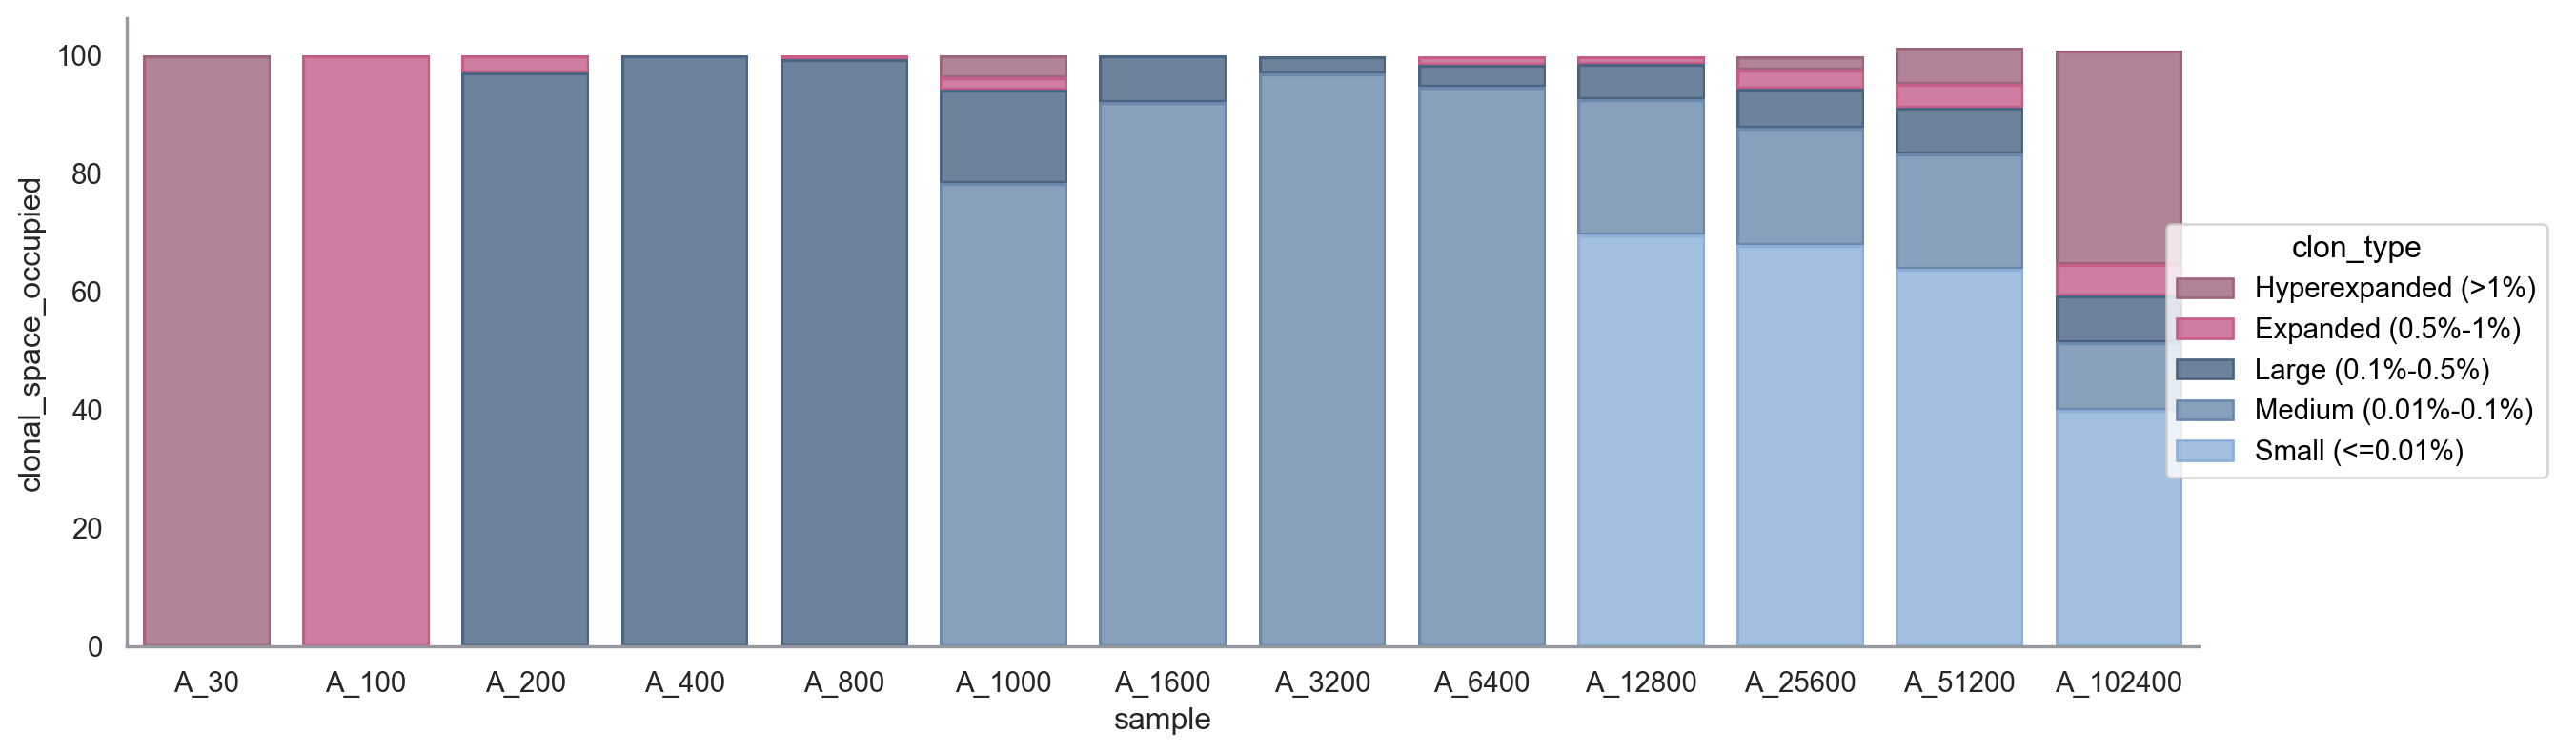

In [11]:
plott = plot_categorized_clones(df_category_summary_gby,"sample", save=False)
plott


In [12]:
df_filter_clone_cat

sample,clone_id,len,perc,clon_type
str,i64,u32,f64,str
"""A_102400""",30795,10373,10.1305,"""Hyperexpanded (>1%)"""
"""A_102400""",27422,6485,6.3334,"""Hyperexpanded (>1%)"""
"""A_102400""",29141,5469,5.3411,"""Hyperexpanded (>1%)"""
"""A_102400""",23153,4613,4.5051,"""Hyperexpanded (>1%)"""
"""A_30""",13,1,3.3333,"""Hyperexpanded (>1%)"""
"""A_30""",25,1,3.3333,"""Hyperexpanded (>1%)"""
"""A_30""",20,1,3.3333,"""Hyperexpanded (>1%)"""
"""A_30""",28,1,3.3333,"""Hyperexpanded (>1%)"""
…,…,…,…,…


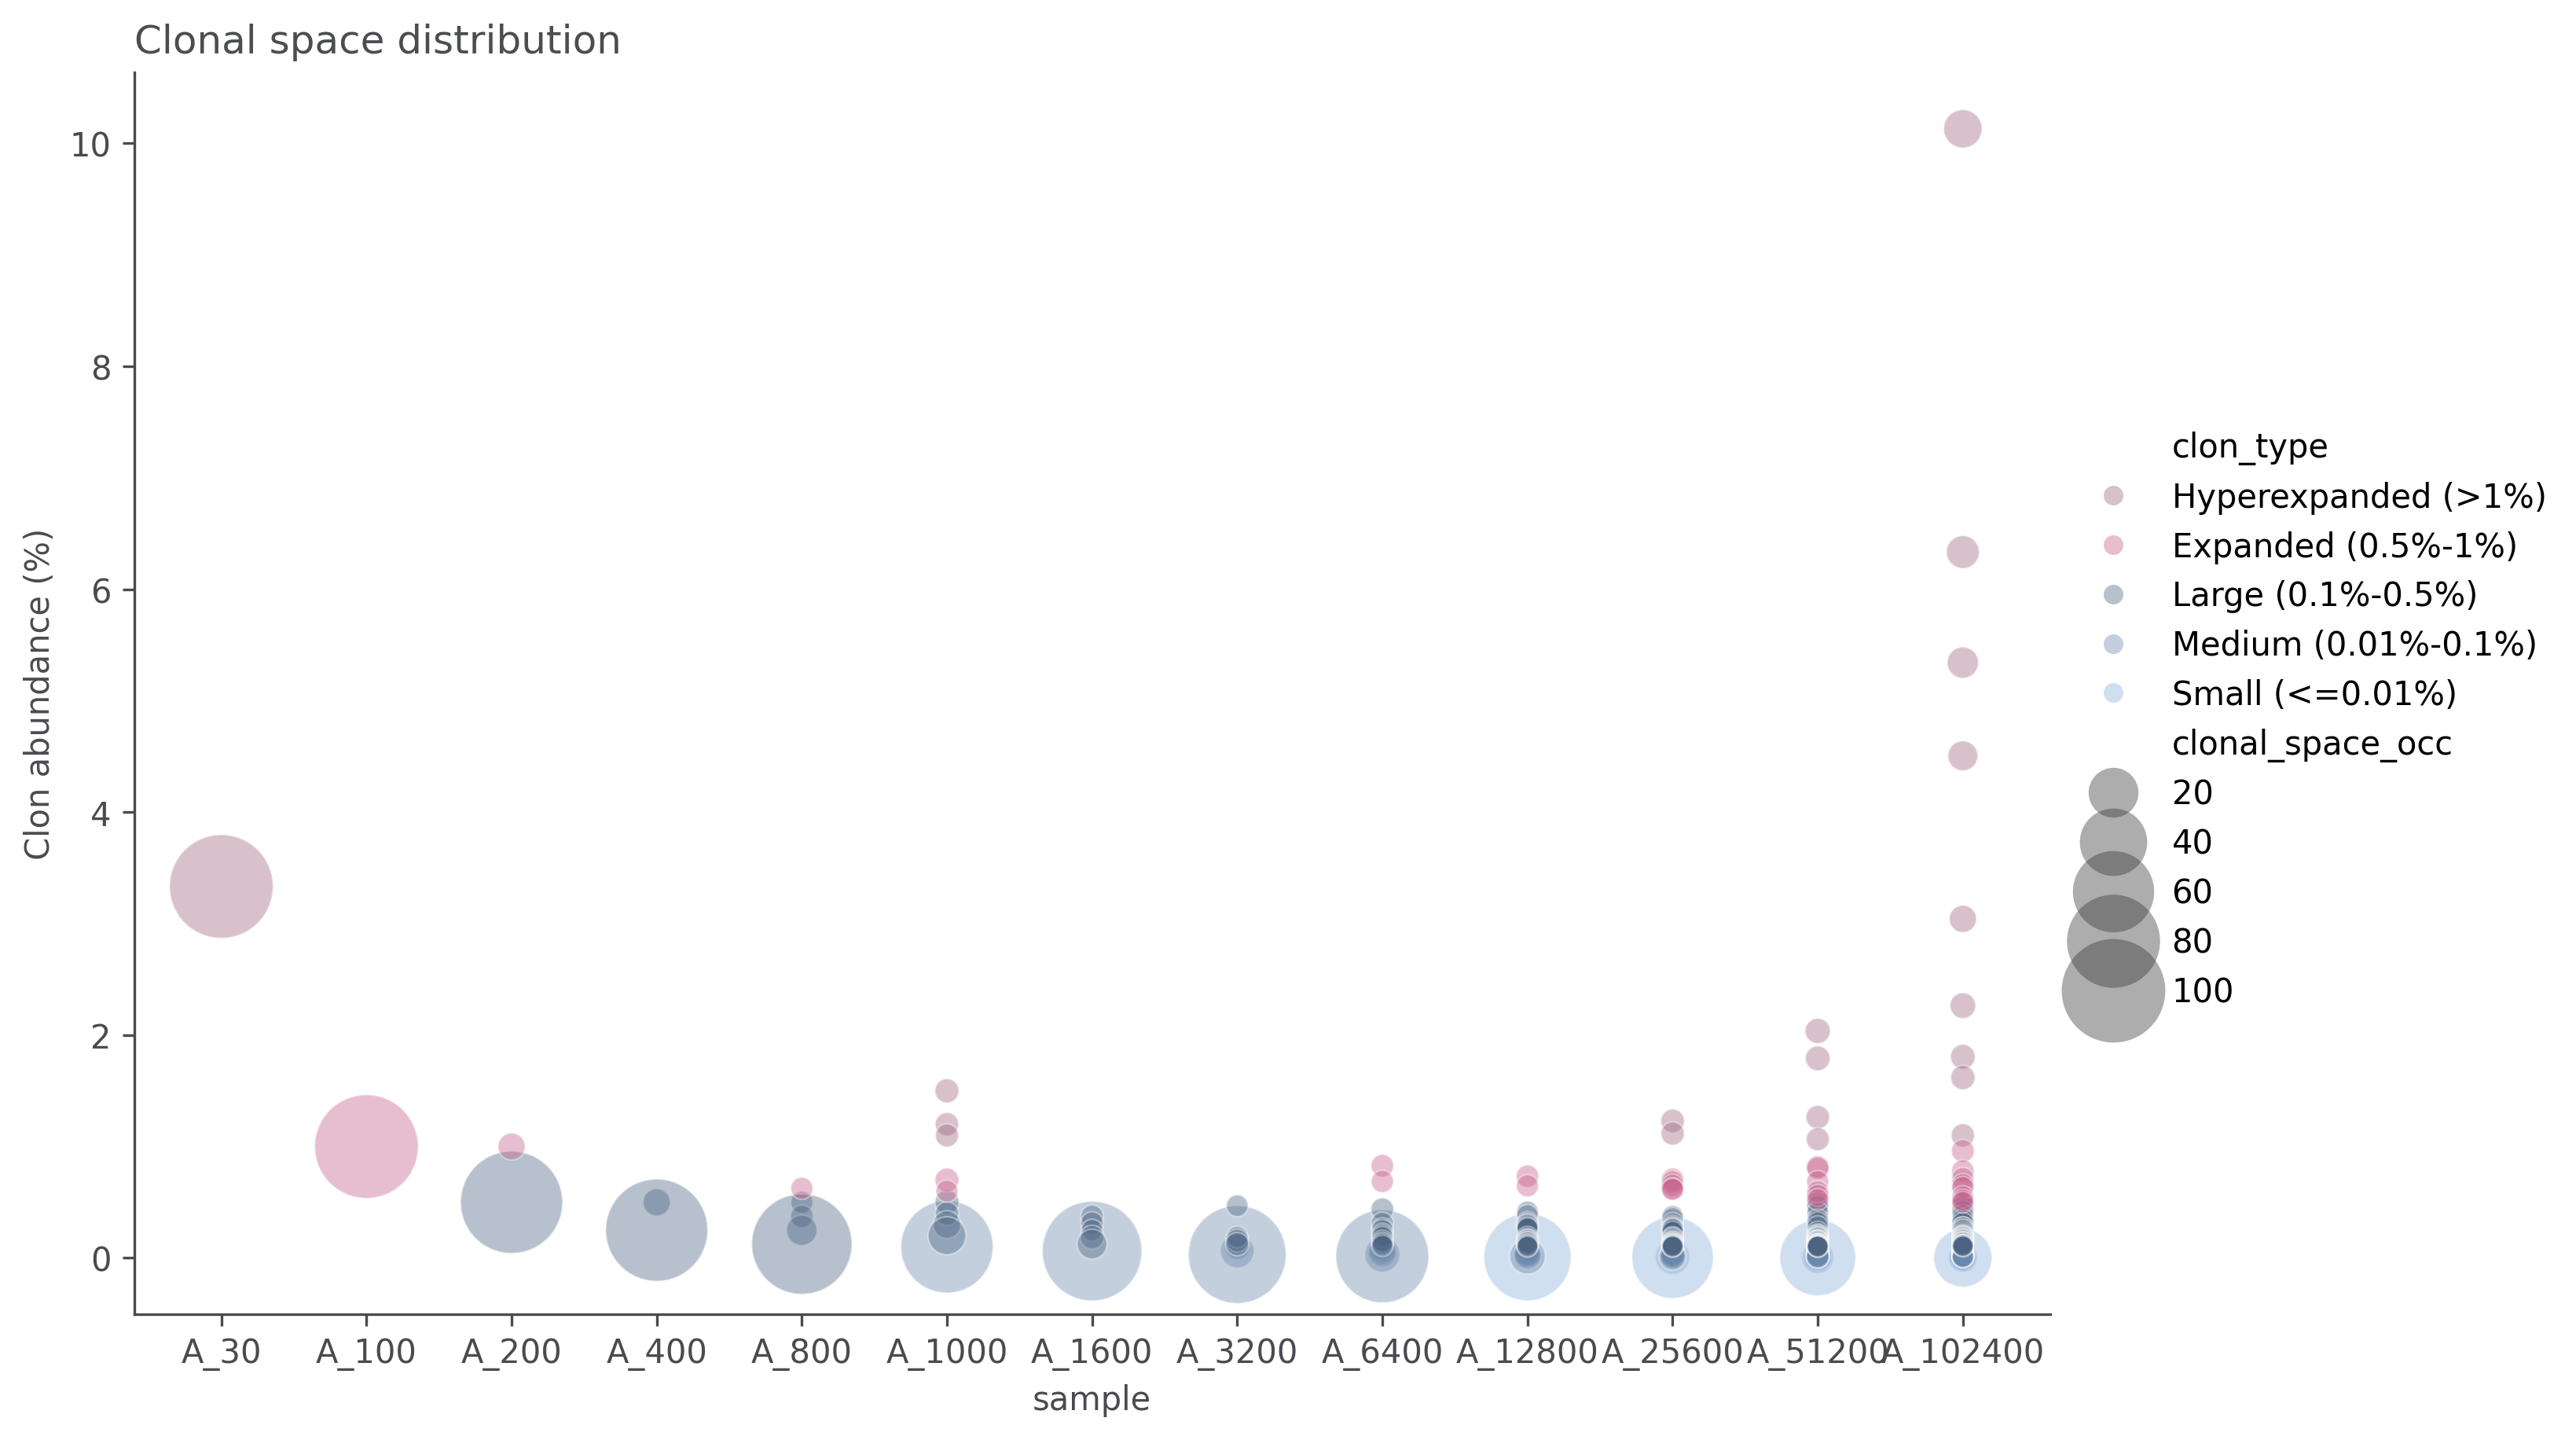

In [13]:
# Agrupamos los clones del mismo tamaño 
df_filter_clone_gby_size =  (df_filter_clone_cat
                             .group_by(["sample","clon_type","len","perc"])
                             .agg(pl.sum("perc").alias("clonal_space_occ"))
                             .sort(["sample","clon_type","len"], descending=True))

# Nueva columna para ordenar el eje X
order_dict = {nombre: i for i, nombre in enumerate(order_samples, start=1)}   
df_category_summary=(df_filter_clone_gby_size
                     .with_columns(order = pl.col("sample").replace(order_dict).cast(pl.Int64)     
                    )

                     .sort("order"))

# alpha indica la transparencia
# sizes indica el tamaño de los círculos, en este caso el rango es de 40 a 1000 para que se logren ver
plot = (sns.relplot(data=df_category_summary, 
                    x="sample",y="perc", hue="clon_type", size="clonal_space_occ",palette=colormap,
                    sizes=(40, 1000), alpha=0.4, height=6, aspect=1.5, legend=True))

# Modificaciones estéticas al gráfico (color de los ejes, rotación ticks, labels, etc)
for ax in plot.axes.flat:
    ax.spines['bottom'].set_color('#4a4b4f')
    ax.spines['left'].set_color('#4a4b4f')

    ax.tick_params(axis='x', colors='#4a4b4f',rotation=0, )
    ax.tick_params(axis='y', colors='#4a4b4f')
    
    ax.set_xlabel(ax.get_xlabel(), color='#4a4b4f')
    ax.set_ylabel("Clon abundance (%)", color='#4a4b4f')
    ax.set_title("Clonal space distribution", loc="left",color='#4b4d50')

plt.savefig("clonal_space_distribution.svg", format="svg", bbox_inches="tight")

# Cada ciruclo es un conjunto de clones que tienen la misma cantidad de lecturas
# el tamaño del círculo es el porcentaje de ocupancia del clon en la muestra
# el color es la categoría según el porcentaje de ocupancia.


In [14]:
df_category_summary.filter(pl.col("sample") == "A_200")

sample,clon_type,len,perc,clonal_space_occ,order
str,str,u32,f64,f64,i64
"""A_200""","""Large (0.1%-0.5%)""",1,0.5,97.0,3
"""A_200""","""Expanded (0.5%-1%)""",2,1.0,3.0,3
